In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp, wasserstein_distance
from scipy.spatial.distance import jensenshannon

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [2]:
from analysis_data import load_analysis_frame

analysis_frame = load_analysis_frame("train")
test_analysis_frame = load_analysis_frame("test")

assert isinstance(analysis_frame, pl.DataFrame)
assert isinstance(test_analysis_frame, pl.DataFrame)

train_shift = analysis_frame.drop("status_penanganan")

test_shift = test_analysis_frame.drop("status_penanganan") if (
    "status_penanganan" in test_analysis_frame.columns
) else test_analysis_frame.clone()

print(f"Train: {train_shift.shape}")
print(f"Test : {test_shift.shape}")

assert "shipment_id" in train_shift.columns
assert "shipment_id" in test_shift.columns

assert train_shift["shipment_id"].n_unique() == train_shift.height
assert test_shift["shipment_id"].n_unique() == test_shift.height

Train: (1243617, 163)
Test : (362245, 163)


In [3]:
train_columns = set(train_shift.columns)
test_columns = set(test_shift.columns)

common_columns = sorted(
    (train_columns & test_columns) - {"shipment_id"}
)

train_only_columns = sorted(train_columns - test_columns)
test_only_columns = sorted(test_columns - train_columns)

print(f"Jumlah fitur yang sama: {len(common_columns)}")
print(f"Kolom khusus train: {train_only_columns}")
print(f"Kolom khusus test: {test_only_columns}")

train_shift = train_shift.select(common_columns)
test_shift = test_shift.select(common_columns)

assert train_shift.columns == test_shift.columns

Jumlah fitur yang sama: 162
Kolom khusus train: []
Kolom khusus test: []


In [4]:
SAMPLE_SIZE = 200_000

train_sample_size = min(SAMPLE_SIZE, train_shift.height)
test_sample_size = min(SAMPLE_SIZE, test_shift.height)

train_sample = (
    train_shift
    .sample(n=train_sample_size, seed=RANDOM_STATE)
    .to_pandas()
)

test_sample = (
    test_shift
    .sample(n=test_sample_size, seed=RANDOM_STATE)
    .to_pandas()
)

print(f"Train sample: {train_sample.shape}")
print(f"Test sample : {test_sample.shape}")

Train sample: (200000, 162)
Test sample : (200000, 162)


In [5]:
categorical_id_features = [
    "hub_id",
    "package_id",
    "promo_id",
    "courier_id",
    "customer_id",
    "cour_shift_code"
]

categorical_id_features = [
    col for col in categorical_id_features
    if col in common_columns
]

numeric_features = [
    col for col in common_columns
    if pd.api.types.is_numeric_dtype(train_sample[col])
    and col not in categorical_id_features
    and pd.api.types.is_numeric_dtype(test_sample[col])
]

categorical_features = [
    col for col in common_columns
    if col not in numeric_features
]

categorical_features = list(
    dict.fromkeys(categorical_features + categorical_id_features)
)

print(f"Fitur numerik: {len(numeric_features)}")
print(f"Fitur kategorikal: {len(categorical_features)}")

Fitur numerik: 133
Fitur kategorikal: 29


In [6]:
missing_shift = pd.DataFrame({
    "Feature": common_columns,
    "Train Missing (%)": [
        train_shift[col].null_count() / train_shift.height * 100
        for col in common_columns
    ],
    "Test Missing (%)": [
        test_shift[col].null_count() / test_shift.height * 100
        for col in common_columns
    ]
})

missing_shift["Absolute Difference (%)"] = (
    missing_shift["Train Missing (%)"]
    - missing_shift["Test Missing (%)"]
).abs()

missing_shift = missing_shift.sort_values(
    "Absolute Difference (%)",
    ascending=False
).reset_index(drop=True)

display(missing_shift.head(50))

,Feature,Train Missing (%),Test Missing (%),Absolute Difference (%)
0,volume_l,2.976157,3.040208,0.064050
1,promo_bulan_akhir,83.016556,82.955458,0.061097
2,promo_bulan_mulai,83.016556,82.955458,0.061097
3,promo_diskon_persen,83.016556,82.955458,0.061097
4,cust_credit_score,2.003832,2.017419,0.013587
5,rt_duration_mean,0.718388,0.710569,0.007820
6,rt_speed_mean,0.718388,0.710569,0.007820
7,rt_duration_max,0.718388,0.710569,0.007820
8,cour_courier_score,1.075733,1.072203,0.003531
9,channel,0.000000,0.000000,0.000000


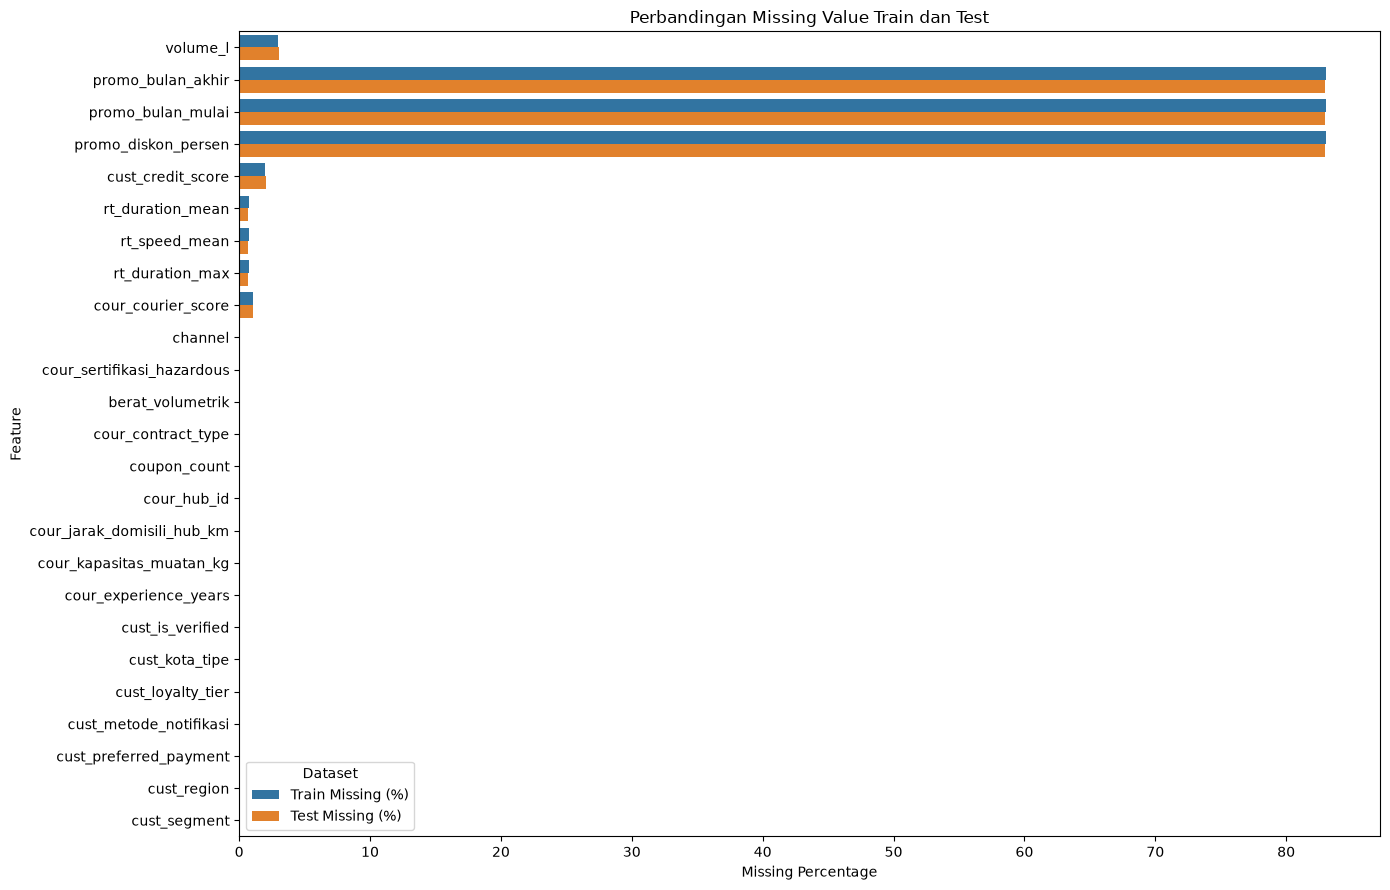

In [7]:
missing_plot = missing_shift.head(25).melt(
    id_vars="Feature",
    value_vars=["Train Missing (%)", "Test Missing (%)"],
    var_name="Dataset",
    value_name="Missing Percentage"
)

plt.figure(figsize=(14, 9))

sns.barplot(
    data=missing_plot,
    x="Missing Percentage",
    y="Feature",
    hue="Dataset"
)

plt.title("Perbandingan Missing Value Train dan Test")
plt.tight_layout()
plt.show()

In [8]:
missing_shift["Missing Shift Category"] = pd.cut(
    missing_shift["Absolute Difference (%)"],
    bins=[-np.inf, 0.5, 2, 5, np.inf],
    labels=["Rendah", "Sedang", "Tinggi", "Sangat Tinggi"]
)

display(
    missing_shift[
        missing_shift["Absolute Difference (%)"] >= 2
    ]
)

,Feature,Train Missing (%),Test Missing (%),Absolute Difference (%),Missing Shift Category


In [9]:
ks_results = []

for feature in numeric_features:
    train_values = (
        pd.to_numeric(train_sample[feature], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    test_values = (
        pd.to_numeric(test_sample[feature], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if len(train_values) < 2 or len(test_values) < 2:
        continue

    statistic, p_value = ks_2samp(
        train_values,
        test_values
    )

    ks_results.append({
        "Feature": feature,
        "KS Statistic": statistic,
        "P Value": p_value,
        "Train Mean": train_values.mean(),
        "Test Mean": test_values.mean(),
        "Train Median": train_values.median(),
        "Test Median": test_values.median()
    })

ks_results = (
    pd.DataFrame(ks_results)
    .sort_values("KS Statistic", ascending=False)
    .reset_index(drop=True)
)

display(ks_results.head(50))

,Feature,KS Statistic,P Value,Train Mean,Test Mean,Train Median,Test Median
0,sc_quality_mean,0.037535,7.562298e-123,3.636886,3.585683,3.666667,3.600000
1,sc_quality_median,0.035065,2.911978e-107,3.687663,3.634890,4.000000,4.000000
2,ship_month,0.030835,4.893589e-83,6.768230,6.925035,7.000000,7.000000
3,sc_quality_min,0.029390,1.786430e-75,2.696315,2.636580,3.000000,3.000000
4,sc_gap_mean,0.024865,3.841248e-54,8.399897,8.643176,7.636000,7.848820
5,rt_speed_mean,0.022014,3.176584e-42,41.856586,41.088432,39.331104,38.622505
6,sc_gap_median,0.021830,7.905048e-42,7.041675,7.245059,6.260000,6.430000
7,sc_manual_rate,0.021630,4.498801e-41,0.178211,0.187451,0.166667,0.166667
8,sc_manual_count,0.021520,1.162757e-40,0.980340,1.031530,1.000000,1.000000
9,sc_gap_max,0.021180,2.122548e-39,17.916605,18.441343,15.480000,15.910000


In [10]:
def classify_ks(value):
    if value < 0.05:
        return "Sangat Rendah"
    if value < 0.10:
        return "Rendah"
    if value < 0.20:
        return "Sedang"
    return "Tinggi"

ks_results["Shift Category"] = (
    ks_results["KS Statistic"].apply(classify_ks)
)

display(
    ks_results.groupby("Shift Category")
    .size()
    .rename("Jumlah Fitur")
    .reset_index()
)

,Shift Category,Jumlah Fitur
0,Sangat Rendah,133


In [11]:
def calculate_psi_numeric(
    train_values,
    test_values,
    bins=10
):
    train_values = pd.Series(train_values).replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    test_values = pd.Series(test_values).replace(
        [np.inf, -np.inf],
        np.nan
    ).dropna()

    if len(train_values) == 0 or len(test_values) == 0:
        return np.nan

    quantiles = np.linspace(0, 1, bins + 1)

    edges = np.unique(
        np.quantile(train_values, quantiles)
    )

    if len(edges) < 3:
        return np.nan

    edges[0] = -np.inf
    edges[-1] = np.inf

    train_bins = pd.cut(
        train_values,
        bins=edges,
        include_lowest=True
    )

    test_bins = pd.cut(
        test_values,
        bins=edges,
        include_lowest=True
    )

    train_distribution = (
        train_bins.value_counts(sort=False)
        / len(train_values)
    )

    test_distribution = (
        test_bins.value_counts(sort=False)
        / len(test_values)
    )

    epsilon = 1e-6

    train_distribution = train_distribution.clip(lower=epsilon)
    test_distribution = test_distribution.clip(lower=epsilon)

    psi = (
        (test_distribution - train_distribution)
        * np.log(test_distribution / train_distribution)
    ).sum()

    return float(psi)

In [12]:
psi_numeric_results = []

for feature in numeric_features:
    psi_value = calculate_psi_numeric(
        train_sample[feature],
        test_sample[feature]
    )

    psi_numeric_results.append({
        "Feature": feature,
        "PSI": psi_value
    })

psi_numeric_results = (
    pd.DataFrame(psi_numeric_results)
    .sort_values("PSI", ascending=False)
    .reset_index(drop=True)
)

display(psi_numeric_results.head(50))

,Feature,PSI
0,sc_quality_mean,0.007975
1,sc_quality_median,0.006445
2,ship_month,0.004922
3,sc_quality_min,0.004603
4,sc_gap_mean,0.003548
5,sc_gap_median,0.002747
6,rt_speed_mean,0.002704
7,sc_gap_max,0.002645
8,sc_gap_sum,0.002514
9,sc_gap_std,0.002108


In [13]:
wasserstein_results = []

for feature in numeric_features:
    train_values = (
        pd.to_numeric(train_sample[feature], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    test_values = (
        pd.to_numeric(test_sample[feature], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if len(train_values) == 0 or len(test_values) == 0:
        continue

    distance = wasserstein_distance(
        train_values,
        test_values
    )

    iqr = (
        train_values.quantile(0.75)
        - train_values.quantile(0.25)
    )

    normalized_distance = (
        distance / iqr if iqr > 0 else np.nan
    )

    wasserstein_results.append({
        "Feature": feature,
        "Wasserstein Distance": distance,
        "Train IQR": iqr,
        "Normalized Wasserstein": normalized_distance
    })

wasserstein_results = (
    pd.DataFrame(wasserstein_results)
    .sort_values("Normalized Wasserstein", ascending=False)
    .reset_index(drop=True)
)

display(wasserstein_results.head(50))

,Feature,Wasserstein Distance,Train IQR,Normalized Wasserstein
0,sc_quality_mean,0.051206,0.750000,0.068275
1,sc_quality_min,0.059735,1.000000,0.059735
2,sc_quality_median,0.052772,1.000000,0.052772
3,sc_gap_mean,0.243365,4.786666,0.050842
4,sc_gap_median,0.203408,4.390000,0.046334
5,sc_gap_max,0.525689,11.839999,0.044399
6,rt_speed_mean,0.768518,18.049168,0.042579
7,sc_gap_std,0.186651,4.492696,0.041546
8,sc_gap_sum,1.321976,32.549999,0.040614
9,sc_manual_rate,0.009241,0.285714,0.032342


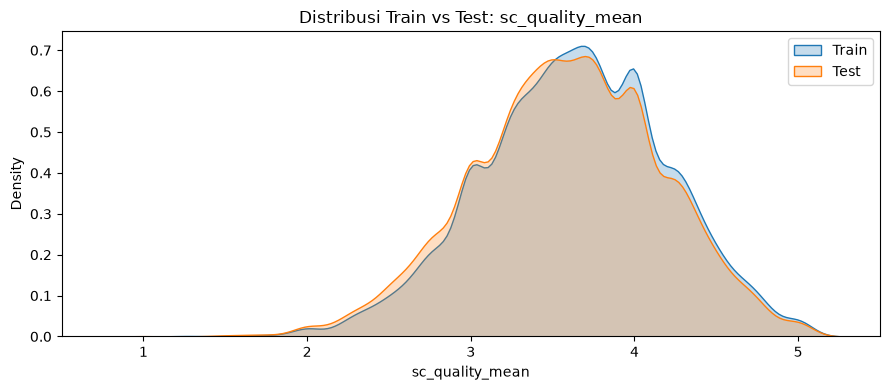

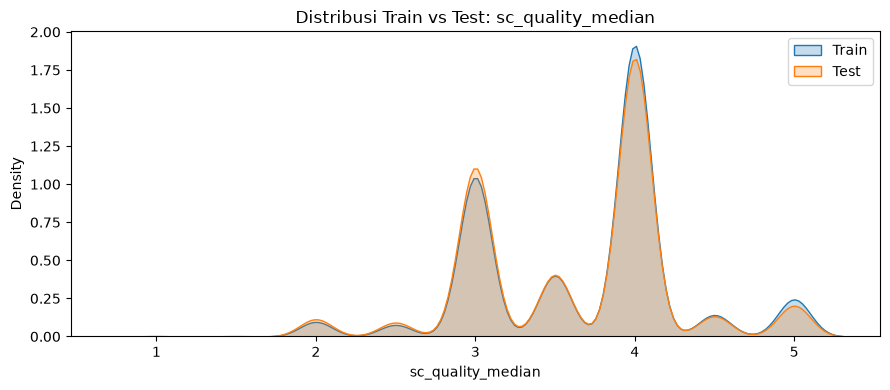

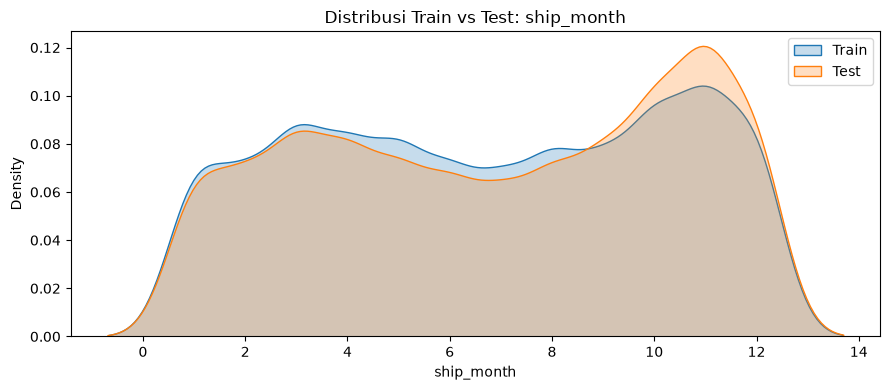

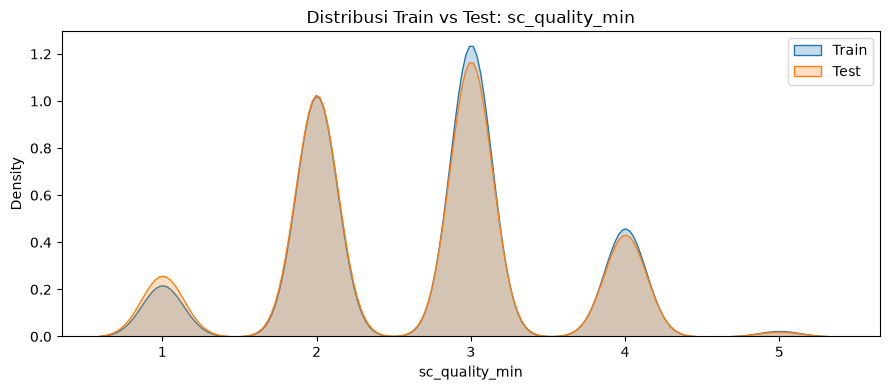

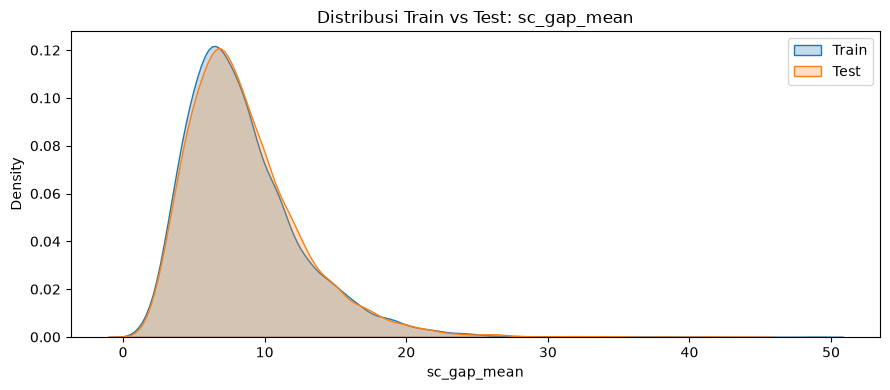

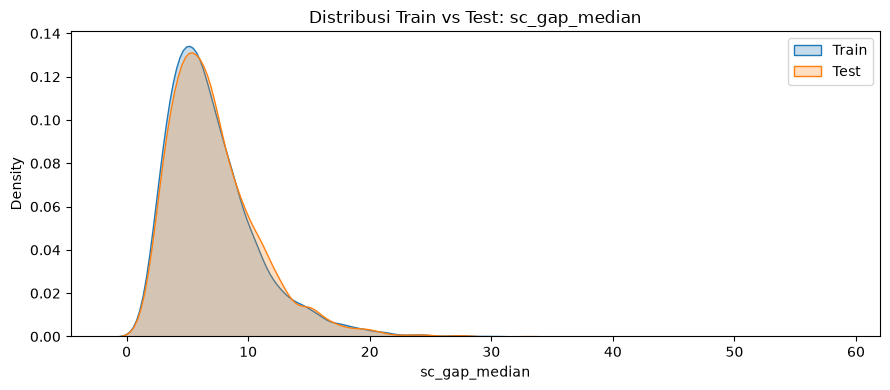

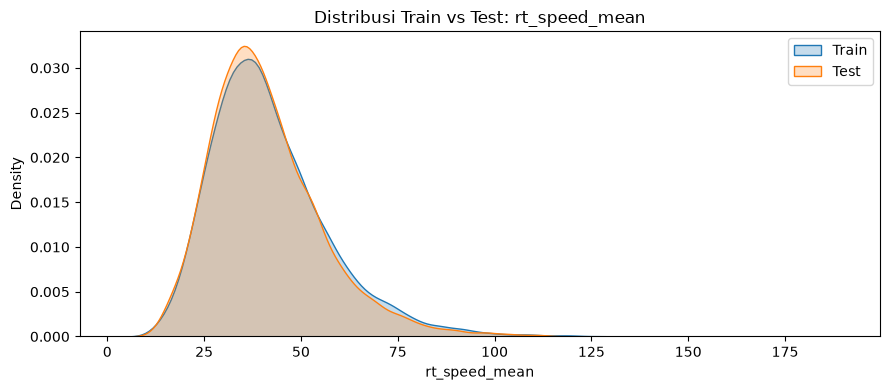

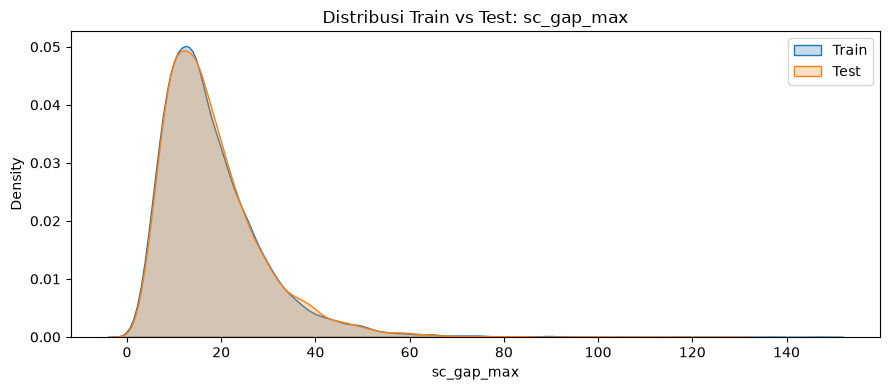

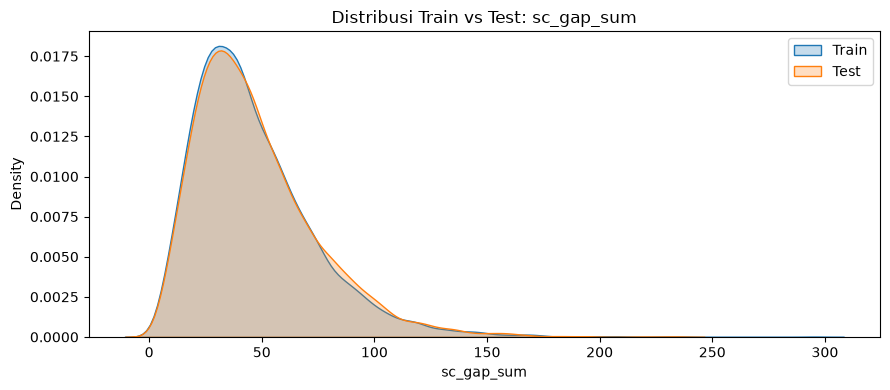

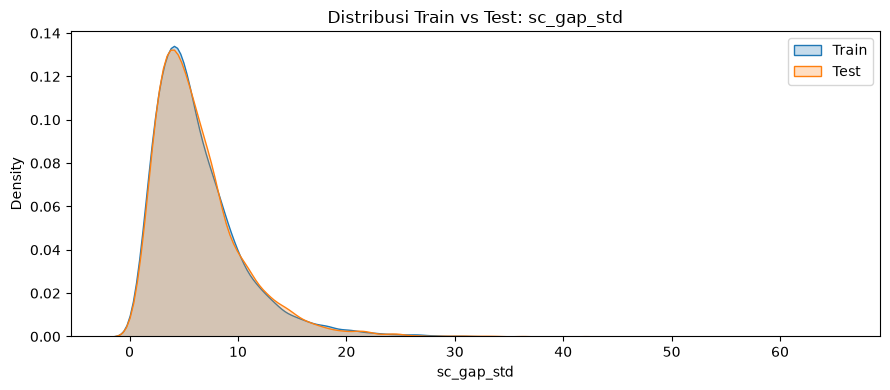

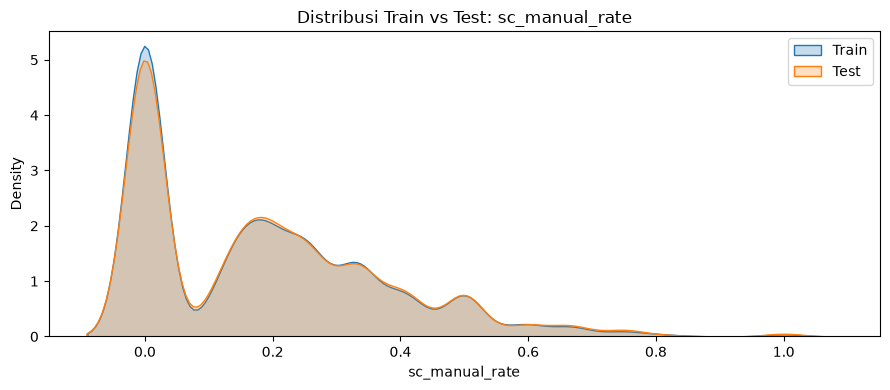

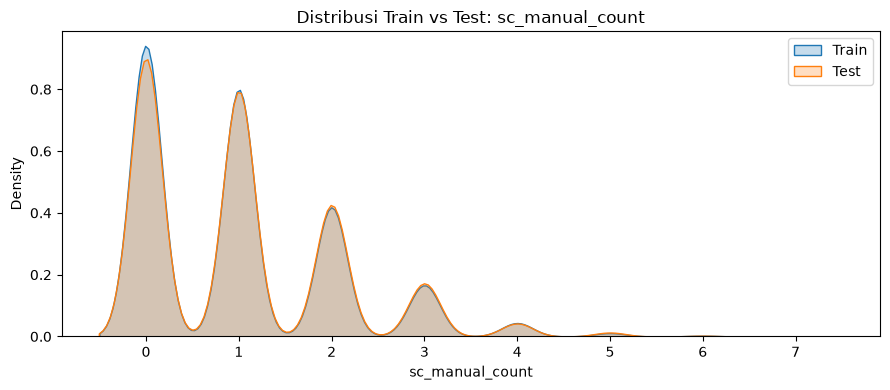

In [14]:
top_numeric_shift = (
    psi_numeric_results
    .dropna()
    .head(12)["Feature"]
    .tolist()
)

for feature in top_numeric_shift:
    train_values = (
        pd.to_numeric(train_sample[feature], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    test_values = (
        pd.to_numeric(test_sample[feature], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    plt.figure(figsize=(9, 4))

    sns.kdeplot(
        train_values.sample(
            min(10_000, len(train_values)),
            random_state=RANDOM_STATE
        ),
        label="Train",
        fill=True
    )

    sns.kdeplot(
        test_values.sample(
            min(10_000, len(test_values)),
            random_state=RANDOM_STATE
        ),
        label="Test",
        fill=True
    )

    plt.title(f"Distribusi Train vs Test: {feature}")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [15]:
unseen_results = []

for feature in categorical_features:
    train_categories = set(
        train_sample[feature]
        .dropna()
        .astype(str)
        .unique()
    )

    test_values = test_sample[feature].dropna().astype(str)

    test_categories = set(test_values.unique())

    unseen_categories = test_categories - train_categories

    unseen_rows = test_values.isin(unseen_categories).sum()

    unseen_results.append({
        "Feature": feature,
        "Train Unique Categories": len(train_categories),
        "Test Unique Categories": len(test_categories),
        "Unseen Category Count": len(unseen_categories),
        "Unseen Test Rows": unseen_rows,
        "Unseen Test Rows (%)": (
            unseen_rows / len(test_values) * 100
            if len(test_values) > 0 else np.nan
        ),
        "Unseen Categories": list(unseen_categories)[:20]
    })

unseen_results = (
    pd.DataFrame(unseen_results)
    .sort_values("Unseen Test Rows (%)", ascending=False)
    .reset_index(drop=True)
)

display(unseen_results)

,Feature,Train Unique Categories,Test Unique Categories,Unseen Category Count,Unseen Test Rows,Unseen Test Rows (%),Unseen Categories
0,customer_id,168896,168824,119259,141184,70.5920,"[CUS-NRLKSAMC, CUS-ZTZKEQAW, CUS-QVDFKYDX, CUS..."
1,courier_id,23802,23801,4,35,0.0175,"[CRV-JTUPC5VF, CRV-59TJ9YPU, CRV-6EJLKSTU, CRV..."
2,cour_hub_id,654,654,0,0,0.0000,[]
3,cour_contract_type,3,3,0,0,0.0000,[]
4,channel,4,4,0,0,0.0000,[]
5,cour_vehicle_type,4,4,0,0,0.0000,[]
6,cour_shift_code,3,3,0,0,0.0000,[]
7,cust_loyalty_tier,4,4,0,0,0.0000,[]
8,cust_kota_tipe,3,3,0,0,0.0000,[]
9,cust_metode_notifikasi,4,4,0,0,0.0000,[]


In [16]:
def calculate_psi_categorical(
    train_values,
    test_values,
    max_categories=100
):
    train_values = (
        pd.Series(train_values)
        .fillna("__MISSING__")
        .astype(str)
    )

    test_values = (
        pd.Series(test_values)
        .fillna("__MISSING__")
        .astype(str)
    )

    top_categories = (
        train_values.value_counts()
        .head(max_categories)
        .index
        .tolist()
    )

    train_grouped = train_values.where(
        train_values.isin(top_categories),
        "__OTHER__"
    )

    test_grouped = test_values.where(
        test_values.isin(top_categories),
        "__OTHER__"
    )

    categories = sorted(
        set(train_grouped.unique())
        | set(test_grouped.unique())
    )

    train_distribution = (
        train_grouped.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    test_distribution = (
        test_grouped.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    epsilon = 1e-6

    train_distribution = train_distribution.clip(lower=epsilon)
    test_distribution = test_distribution.clip(lower=epsilon)

    psi = (
        (test_distribution - train_distribution)
        * np.log(test_distribution / train_distribution)
    ).sum()

    return float(psi)

In [17]:
psi_categorical_results = []

for feature in categorical_features:
    psi_value = calculate_psi_categorical(
        train_sample[feature],
        test_sample[feature]
    )

    psi_categorical_results.append({
        "Feature": feature,
        "PSI": psi_value
    })

psi_categorical_results = (
    pd.DataFrame(psi_categorical_results)
    .sort_values("PSI", ascending=False)
    .reset_index(drop=True)
)

display(psi_categorical_results.head(50))

,Feature,PSI
0,customer_id,4.946103e-03
1,courier_id,4.629407e-03
2,cour_hub_id,1.049686e-03
3,hub_id,1.049686e-03
4,package_id,6.473649e-04
5,kota_asal,4.559049e-04
6,kota_tujuan,3.521690e-04
7,promo_id,3.520954e-04
8,promo_nama_promo,1.927273e-04
9,hub_region,9.487223e-05


In [18]:
def calculate_js_categorical(train_values, test_values):
    train_values = (
        pd.Series(train_values)
        .fillna("__MISSING__")
        .astype(str)
    )

    test_values = (
        pd.Series(test_values)
        .fillna("__MISSING__")
        .astype(str)
    )

    categories = sorted(
        set(train_values.unique())
        | set(test_values.unique())
    )

    train_distribution = (
        train_values.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    test_distribution = (
        test_values.value_counts(normalize=True)
        .reindex(categories, fill_value=0)
    )

    return float(
        jensenshannon(
            train_distribution,
            test_distribution
        )
    )

js_categorical_results = []

for feature in categorical_features:
    js_value = calculate_js_categorical(
        train_sample[feature],
        test_sample[feature]
    )

    js_categorical_results.append({
        "Feature": feature,
        "Jensen-Shannon Distance": js_value
    })

js_categorical_results = (
    pd.DataFrame(js_categorical_results)
    .sort_values("Jensen-Shannon Distance", ascending=False)
    .reset_index(drop=True)
)

display(js_categorical_results.head(50))

,Feature,Jensen-Shannon Distance
0,customer_id,0.704938
1,courier_id,0.174684
2,cour_hub_id,0.027663
3,hub_id,0.027663
4,package_id,0.008995
5,kota_asal,0.007549
6,kota_tujuan,0.006635
7,promo_id,0.006634
8,promo_nama_promo,0.004908
9,hub_region,0.003444


In [19]:
ADV_SAMPLE_SIZE = 50_000

train_adv = train_shift.sample(
    n=min(ADV_SAMPLE_SIZE, train_shift.height),
    seed=RANDOM_STATE
).to_pandas()

test_adv = test_shift.sample(
    n=min(ADV_SAMPLE_SIZE, test_shift.height),
    seed=RANDOM_STATE
).to_pandas()

adv_data = pd.concat(
    [train_adv, test_adv],
    ignore_index=True
)

adv_target = np.concatenate([
    np.zeros(len(train_adv), dtype=int),
    np.ones(len(test_adv), dtype=int)
])

adv_data = adv_data[common_columns].copy()

print(f"Jumlah observasi adversarial: {len(adv_data):,}")
print(f"Train domain: {(adv_target == 0).sum():,}")
print(f"Test domain : {(adv_target == 1).sum():,}")

Jumlah observasi adversarial: 100,000
Train domain: 50,000
Test domain : 50,000


In [20]:
MAX_ADV_CATEGORIES = 100

adv_numeric_features = [
    col for col in numeric_features
    if adv_data[col].nunique(dropna=True) > 1
]

adv_categorical_features = [
    col for col in categorical_features
    if adv_data[col].nunique(dropna=True) <= 1000
]

for feature in adv_categorical_features:
    top_categories = (
        adv_data[feature]
        .fillna("__MISSING__")
        .astype(str)
        .value_counts()
        .head(MAX_ADV_CATEGORIES)
        .index
    )

    adv_data[feature] = (
        adv_data[feature]
        .fillna("__MISSING__")
        .astype(str)
        .where(
            adv_data[feature]
            .fillna("__MISSING__")
            .astype(str)
            .isin(top_categories),
            "__OTHER__"
        )
    )

adv_feature_columns = (
    adv_numeric_features
    + adv_categorical_features
)

adv_data = adv_data[adv_feature_columns]

print(f"Fitur numerik: {len(adv_numeric_features)}")
print(f"Fitur kategorikal: {len(adv_categorical_features)}")

Fitur numerik: 131
Fitur kategorikal: 27


In [21]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="__MISSING__"
        )
    ),
    (
        "encoder",
        OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_transformer,
        adv_numeric_features
    ),
    (
        "categorical",
        categorical_transformer,
        adv_categorical_features
    )
])

adversarial_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        ExtraTreesClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=20,
            max_features=0.8,
            class_weight="balanced",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )
    )
])

In [22]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

adversarial_auc = cross_val_score(
    adversarial_model,
    adv_data,
    adv_target,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1
)

print(f"ROC-AUC per fold: {adversarial_auc}")
print(f"Mean ROC-AUC: {adversarial_auc.mean():.5f}")
print(f"Std ROC-AUC : {adversarial_auc.std():.5f}")

ROC-AUC per fold: [0.53790821 0.53016091 0.53505141 0.52938074 0.52860049]
Mean ROC-AUC: 0.53222
Std ROC-AUC : 0.00363


In [23]:
adversarial_model.fit(
    adv_data,
    adv_target
)

feature_importance = (
    adversarial_model
    .named_steps["classifier"]
    .feature_importances_
)

adversarial_importance = pd.DataFrame({
    "Feature": adv_feature_columns,
    "Importance": feature_importance
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(adversarial_importance.head(30))

,Feature,Importance
0,ship_month,0.031798
1,sc_quality_mean,0.025810
2,sc_quality_median,0.019330
3,cour_contract_type,0.011651
4,hub_jam_tutup,0.011345
5,r_volumetric_weight,0.011160
6,dest_region,0.011134
7,cust_preferred_payment,0.011071
8,cour_courier_score,0.011012
9,goods_category,0.011001


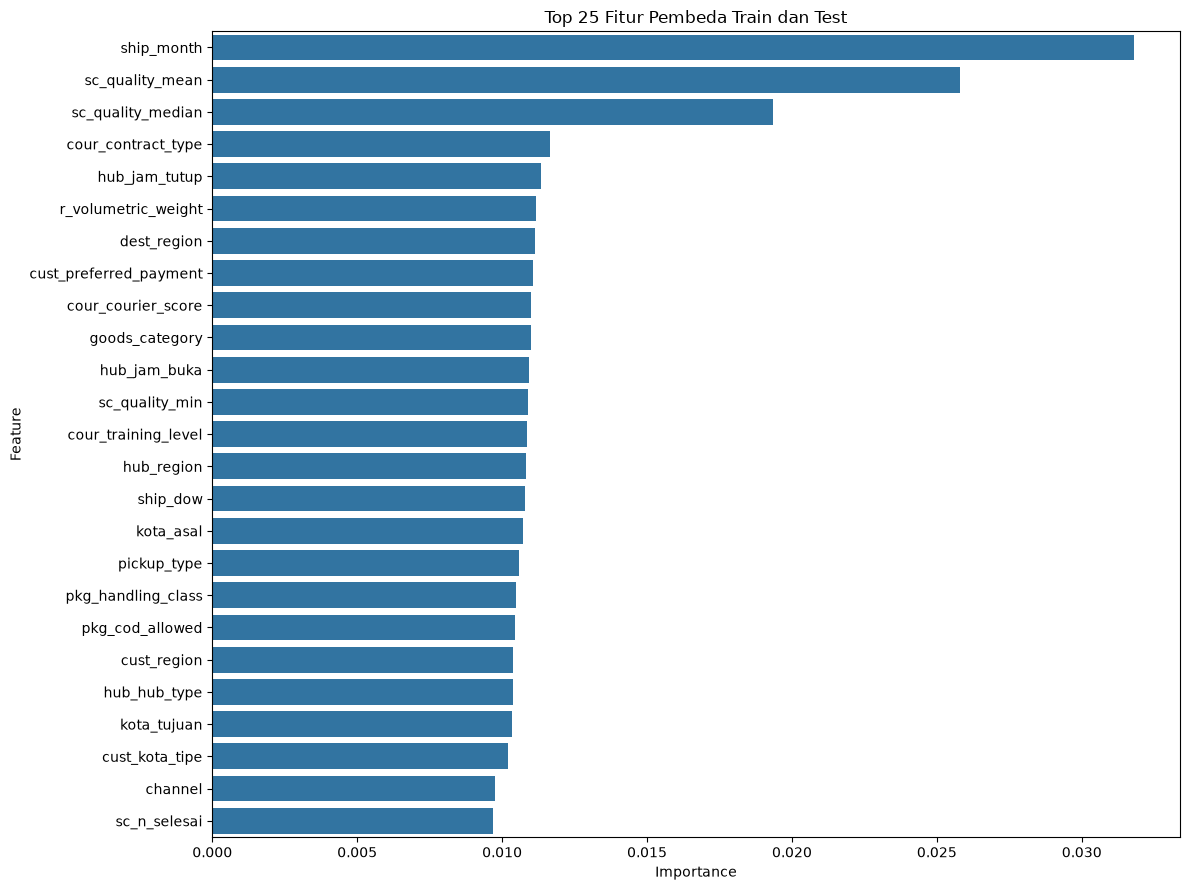

In [24]:
plt.figure(figsize=(12, 9))

sns.barplot(
    data=adversarial_importance.head(25),
    x="Importance",
    y="Feature"
)

plt.title("Top 25 Fitur Pembeda Train dan Test")
plt.tight_layout()
plt.show()

In [25]:
numeric_shift_summary = (
    pd.DataFrame({"Feature": numeric_features})
    .merge(
        ks_results[["Feature", "KS Statistic", "P Value"]],
        on="Feature",
        how="left"
    )
    .merge(
        psi_numeric_results,
        on="Feature",
        how="left"
    )
    .merge(
        wasserstein_results[
            ["Feature", "Normalized Wasserstein"]
        ],
        on="Feature",
        how="left"
    )
    .merge(
        missing_shift,
        on="Feature",
        how="left"
    )
)

numeric_shift_summary = numeric_shift_summary.sort_values(
    "PSI",
    ascending=False
)

display(numeric_shift_summary.head(50))

,Feature,KS Statistic,P Value,PSI,Normalized Wasserstein,Train Missing (%),Test Missing (%),Absolute Difference (%),Missing Shift Category
109,sc_quality_mean,0.037535,7.562298e-123,0.007975,0.068275,0.000000,0.000000,0.000000,Rendah
110,sc_quality_median,0.035065,2.911978e-107,0.006445,0.052772,0.000000,0.000000,0.000000,Rendah
118,ship_month,0.030835,4.893589e-83,0.004922,0.026134,0.000000,0.000000,0.000000,Rendah
111,sc_quality_min,0.029390,1.786430e-75,0.004603,0.059735,0.000000,0.000000,0.000000,Rendah
97,sc_gap_mean,0.024865,3.841248e-54,0.003548,0.050842,0.000000,0.000000,0.000000,Rendah
98,sc_gap_median,0.021830,7.905048e-42,0.002747,0.046334,0.000000,0.000000,0.000000,Rendah
92,rt_speed_mean,0.022014,3.176584e-42,0.002704,0.042579,0.718388,0.710569,0.007820,Rendah
96,sc_gap_max,0.021180,2.122548e-39,0.002645,0.044399,0.000000,0.000000,0.000000,Rendah
100,sc_gap_sum,0.021165,2.410146e-39,0.002514,0.040614,0.000000,0.000000,0.000000,Rendah
99,sc_gap_std,0.019925,6.439078e-35,0.002108,0.041546,0.000000,0.000000,0.000000,Rendah


In [26]:
categorical_shift_summary = (
    pd.DataFrame({"Feature": categorical_features})
    .merge(
        psi_categorical_results,
        on="Feature",
        how="left"
    )
    .merge(
        js_categorical_results,
        on="Feature",
        how="left"
    )
    .merge(
        unseen_results[
            [
                "Feature",
                "Unseen Category Count",
                "Unseen Test Rows (%)"
            ]
        ],
        on="Feature",
        how="left"
    )
    .merge(
        missing_shift,
        on="Feature",
        how="left"
    )
)

categorical_shift_summary = categorical_shift_summary.sort_values(
    "PSI",
    ascending=False
)

display(categorical_shift_summary.head(50))

,Feature,PSI,Jensen-Shannon Distance,Unseen Category Count,Unseen Test Rows (%),Train Missing (%),Test Missing (%),Absolute Difference (%),Missing Shift Category
12,customer_id,4.946103e-03,0.704938,119259,70.5920,0.0,0.0,0.0,Rendah
5,courier_id,4.629407e-03,0.174684,4,0.0175,0.0,0.0,0.0,Rendah
2,cour_hub_id,1.049686e-03,0.027663,0,0.0000,0.0,0.0,0.0,Rendah
16,hub_id,1.049686e-03,0.027663,0,0.0000,0.0,0.0,0.0,Rendah
20,package_id,6.473649e-04,0.008995,0,0.0000,0.0,0.0,0.0,Rendah
18,kota_asal,4.559049e-04,0.007549,0,0.0000,0.0,0.0,0.0,Rendah
19,kota_tujuan,3.521690e-04,0.006635,0,0.0000,0.0,0.0,0.0,Rendah
24,promo_id,3.520954e-04,0.006634,0,0.0000,0.0,0.0,0.0,Rendah
25,promo_nama_promo,1.927273e-04,0.004908,0,0.0000,0.0,0.0,0.0,Rendah
17,hub_region,9.487223e-05,0.003444,0,0.0000,0.0,0.0,0.0,Rendah


In [28]:
def classify_psi(value):
    if pd.isna(value):
        return "Tidak tersedia"
    if value < 0.10:
        return "Rendah"
    if value < 0.25:
        return "Sedang"
    return "Tinggi"

numeric_shift_summary["PSI Category"] = (
    numeric_shift_summary["PSI"].apply(classify_psi)
)

categorical_shift_summary["PSI Category"] = (
    categorical_shift_summary["PSI"].apply(classify_psi)
)

display(
    pd.concat([
        numeric_shift_summary[
            ["Feature", "PSI", "PSI Category"]
        ],
        categorical_shift_summary[
            ["Feature", "PSI", "PSI Category"]
        ]
    ])
    .groupby("PSI Category")
    .size()
    .rename("Jumlah Fitur")
    .reset_index()
)

,PSI Category,Jumlah Fitur
0,Rendah,136
1,Tidak tersedia,26


In [29]:
numeric_priority = numeric_shift_summary[
    (numeric_shift_summary["PSI"] > 0.25)
    | (numeric_shift_summary["KS Statistic"] > 0.20)
    | (numeric_shift_summary["Absolute Difference (%)"] > 2)
].copy()

categorical_priority = categorical_shift_summary[
    (categorical_shift_summary["PSI"] > 0.25)
    | (categorical_shift_summary["Unseen Test Rows (%)"] > 1)
    | (categorical_shift_summary["Absolute Difference (%)"] > 2)
].copy()

print("Fitur numerik yang perlu diinvestigasi")
display(numeric_priority)

print("Fitur kategorikal yang perlu diinvestigasi")
display(categorical_priority)

Fitur numerik yang perlu diinvestigasi


,Feature,KS Statistic,P Value,PSI,Normalized Wasserstein,Train Missing (%),Test Missing (%),Absolute Difference (%),Missing Shift Category,PSI Category


Fitur kategorikal yang perlu diinvestigasi


,Feature,PSI,Jensen-Shannon Distance,Unseen Category Count,Unseen Test Rows (%),Train Missing (%),Test Missing (%),Absolute Difference (%),Missing Shift Category,PSI Category
12,customer_id,0.004946,0.704938,119259,70.592,0.0,0.0,0.0,Rendah,Rendah


In [30]:
OUTPUT_DIR = "section07_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

missing_shift.to_csv(
    f"{OUTPUT_DIR}/missing_value_shift.csv",
    index=False
)

ks_results.to_csv(
    f"{OUTPUT_DIR}/ks_test_results.csv",
    index=False
)

psi_numeric_results.to_csv(
    f"{OUTPUT_DIR}/psi_numeric_results.csv",
    index=False
)

wasserstein_results.to_csv(
    f"{OUTPUT_DIR}/wasserstein_results.csv",
    index=False
)

unseen_results.to_csv(
    f"{OUTPUT_DIR}/unseen_category_results.csv",
    index=False
)

psi_categorical_results.to_csv(
    f"{OUTPUT_DIR}/psi_categorical_results.csv",
    index=False
)

js_categorical_results.to_csv(
    f"{OUTPUT_DIR}/jensen_shannon_results.csv",
    index=False
)

adversarial_importance.to_csv(
    f"{OUTPUT_DIR}/adversarial_feature_importance.csv",
    index=False
)

numeric_shift_summary.to_csv(
    f"{OUTPUT_DIR}/numeric_shift_summary.csv",
    index=False
)

categorical_shift_summary.to_csv(
    f"{OUTPUT_DIR}/categorical_shift_summary.csv",
    index=False
)

numeric_priority.to_csv(
    f"{OUTPUT_DIR}/numeric_priority_investigation.csv",
    index=False
)

categorical_priority.to_csv(
    f"{OUTPUT_DIR}/categorical_priority_investigation.csv",
    index=False
)

print(f"Seluruh hasil tersimpan di folder {OUTPUT_DIR}")

Seluruh hasil tersimpan di folder section07_outputs
